# Multi-Class Benchmark Classification Pipeline (Iris)

**Goal:** Train Logistic Regression and Decision Tree on the Iris dataset and compare accuracy, precision, recall and F1-score.

**Steps:** Load data → EDA (pairplot) → Scale features → 80/20 split → Train models → Evaluate → Confusion matrices → Decision boundaries.

## 1. Import libraries

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)

sns.set_style("whitegrid")
RANDOM_STATE = 42

## 2. Load the dataset with Pandas

In [2]:
df = pd.read_csv("iris.csv")
print("Shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
df.head()

Shape: (150, 5)
Missing values: 0


,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [3]:
print(df['species'].value_counts())
df.describe()

species
setosa        50
versicolor    50
virginica     50
Name: count, dtype: int64


,sepal_length,sepal_width,petal_length,petal_width
count,150.000000,150.000000,150.000000,150.000000
mean,5.843333,3.057333,3.758000,1.199333
std,0.828066,0.435866,1.765298,0.762238
min,4.300000,2.000000,1.000000,0.100000
25%,5.100000,2.800000,1.600000,0.300000
50%,5.800000,3.000000,4.350000,1.300000
75%,6.400000,3.300000,5.100000,1.800000
max,7.900000,4.400000,6.900000,2.500000


## 3. Exploratory pairplot (Seaborn)

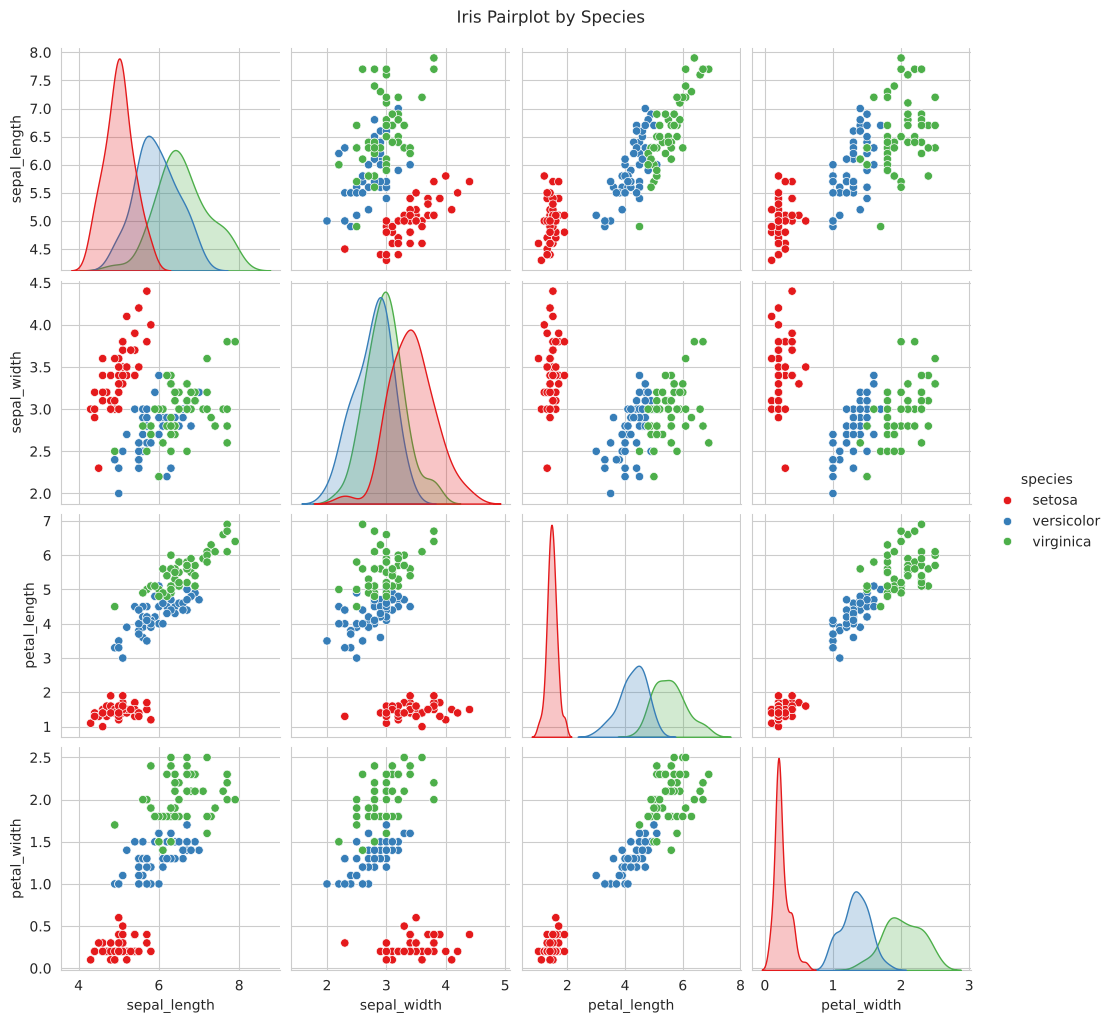

In [4]:
sns.pairplot(df, hue="species", palette="Set1", corner=False)
plt.suptitle("Iris Pairplot by Species", y=1.02)
plt.show()

## 4. Prepare features and target
The species names are converted to numbers (0, 1, 2) so models can use them.

In [5]:
features = ["sepal_length", "sepal_width", "petal_length", "petal_width"]
X = df[features].values
le = LabelEncoder()
y = le.fit_transform(df["species"])
class_names = le.classes_
print("Classes:", dict(zip(class_names, range(len(class_names)))))

Classes: {'setosa': 0, 'versicolor': 1, 'virginica': 2}


## 5. Train/test split (80/20) and feature scaling
`StandardScaler` is **fit on training data only** and then applied to test data, to avoid data leakage.

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y)

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print("Train size:", X_train_s.shape[0], "| Test size:", X_test_s.shape[0])

Train size: 120 | Test size: 30


## 6. Train Logistic Regression and Decision Tree

In [7]:
log_reg = LogisticRegression(max_iter=200, random_state=RANDOM_STATE)
dtree = DecisionTreeClassifier(random_state=RANDOM_STATE)

log_reg.fit(X_train_s, y_train)
dtree.fit(X_train_s, y_train)

models = {"Logistic Regression": log_reg, "Decision Tree": dtree}
preds = {name: m.predict(X_test_s) for name, m in models.items()}
print("Both models trained.")

Both models trained.


## 7. Benchmark: Accuracy, Precision, Recall, F1
Macro averaging treats all 3 classes equally (suits multi-class).

In [8]:
rows = []
for name, y_pred in preds.items():
    rows.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (macro)": precision_score(y_test, y_pred, average="macro"),
        "Recall (macro)": recall_score(y_test, y_pred, average="macro"),
        "F1-score (macro)": f1_score(y_test, y_pred, average="macro"),
    })
results = pd.DataFrame(rows).set_index("Model").round(4)
results

,Accuracy,Precision (macro),Recall (macro),F1-score (macro)
Model,,,,
Logistic Regression,0.9333,0.9333,0.9333,0.9333
Decision Tree,0.9333,0.9333,0.9333,0.9333


In [9]:
for name, y_pred in preds.items():
    print("=" * 60)
    print(name)
    print("=" * 60)
    print(classification_report(y_test, y_pred, target_names=class_names, digits=3))

Logistic Regression
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30

Decision Tree
              precision    recall  f1-score   support

      setosa      1.000     1.000     1.000        10
  versicolor      0.900     0.900     0.900        10
   virginica      0.900     0.900     0.900        10

    accuracy                          0.933        30
   macro avg      0.933     0.933     0.933        30
weighted avg      0.933     0.933     0.933        30



## 8. Confusion matrix heatmaps

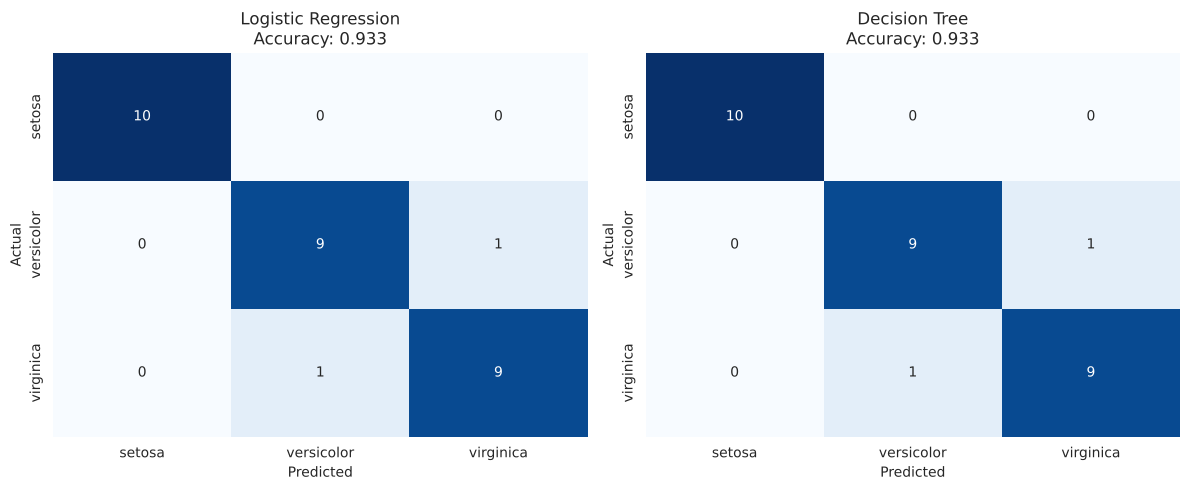

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, y_pred) in zip(axes, preds.items()):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_names, yticklabels=class_names, ax=ax)
    ax.set_title(f"{name}\nAccuracy: {accuracy_score(y_test, y_pred):.3f}")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
plt.tight_layout()
plt.show()

## 9. Decision boundary visualization
Decision boundaries need 2D, so models are re-trained on the two most informative features: **petal length** and **petal width** (scaled).

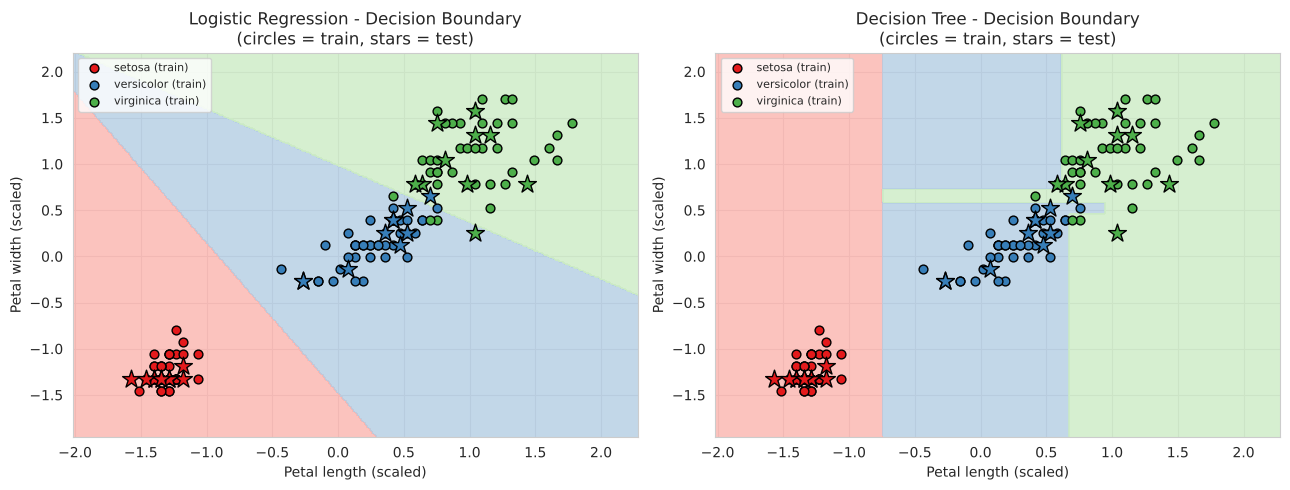

In [11]:
# Use petal_length (index 2) and petal_width (index 3)
idx = [2, 3]
Xtr2, Xte2 = X_train_s[:, idx], X_test_s[:, idx]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ["#e41a1c", "#377eb8", "#4daf4a"]
from matplotlib.colors import ListedColormap
cmap_bg = ListedColormap(["#fbb4ae", "#b3cde3", "#ccebc5"])

for ax, (name, base) in zip(axes, [("Logistic Regression", LogisticRegression(max_iter=200, random_state=RANDOM_STATE)),
                                    ("Decision Tree", DecisionTreeClassifier(random_state=RANDOM_STATE))]):
    base.fit(Xtr2, y_train)
    x_min, x_max = Xtr2[:, 0].min() - 0.5, Xtr2[:, 0].max() + 0.5
    y_min, y_max = Xtr2[:, 1].min() - 0.5, Xtr2[:, 1].max() + 0.5
    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 300), np.linspace(y_min, y_max, 300))
    Z = base.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, cmap=cmap_bg, alpha=0.8)
    for i, cname in enumerate(class_names):
        ax.scatter(Xtr2[y_train == i, 0], Xtr2[y_train == i, 1], c=colors[i],
                   edgecolor="k", s=40, label=f"{cname} (train)")
        ax.scatter(Xte2[y_test == i, 0], Xte2[y_test == i, 1], c=colors[i],
                   edgecolor="k", marker="*", s=180)
    ax.set_title(f"{name} - Decision Boundary\n(circles = train, stars = test)")
    ax.set_xlabel("Petal length (scaled)")
    ax.set_ylabel("Petal width (scaled)")
    ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

## 10. Conclusion


In [12]:
print(results)
f1 = results["F1-score (macro)"]
if f1.nunique() == 1:
    print("\nBoth models tie on macro F1 for this split.")
else:
    print(f"\nBest model by macro F1: {f1.idxmax()}")

                     Accuracy  Precision (macro)  Recall (macro)  \
Model                                                              
Logistic Regression    0.9333             0.9333          0.9333   
Decision Tree          0.9333             0.9333          0.9333   

                     F1-score (macro)  
Model                                  
Logistic Regression            0.9333  
Decision Tree                  0.9333  

Both models tie on macro F1 for this split.


**Observations**
- *Setosa* is perfectly separable from the other two classes (see pairplot and boundaries).
- Most confusion happens between *versicolor* and *virginica*, which overlap in feature space.
- Logistic Regression draws smooth, linear boundaries; the Decision Tree draws rectangular, axis-aligned boundaries and can overfit with default settings.
- Scaling matters most for Logistic Regression; Decision Trees are not sensitive to feature scale.
- On this split both models score the same (93.3%), so neither is clearly better here.
- With only 30 test samples, one wrong prediction changes accuracy by about 3.3%, so results can vary with `random_state`.